# Comparing Different Search Strategies: Maze

Notes on breaking ties:

* The order in which the children are explored (see `available directions`) makes a big difference for DFS and dealing with empty spaces. I explore the directions in random order which makes the algorithm stochastic!
* Ties for $h(n)$ and $f(n)$ need to be broken in a consistent manner. I use the most recently added node. To try to keep moving into the same direction.



In [24]:
import os

# Đường dẫn đến thư mục chứa notebook và các file của bạn trên Drive
folder_path = 'F:\TTNTNC\lab02 - Searching'

# Đổi thư mục làm việc hiện tại sang thư mục này
os.chdir(folder_path)

# Kiểm tra thư mục làm việc hiện tại
print("Thư mục hiện tại:", os.getcwd())

Thư mục hiện tại: F:\TTNTNC\lab02 - Searching


Helper functions for the Maze Assignment by M. Hahsler
Usage: 
  import maze_helper as mh
  mh.show_some_mazes()
  
Here is an example maze:

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX

The goal is at (np.int64(8), np.int64(1)).
Position(0,0): X
Position(8,1):  


<Figure size 640x480 with 0 Axes>

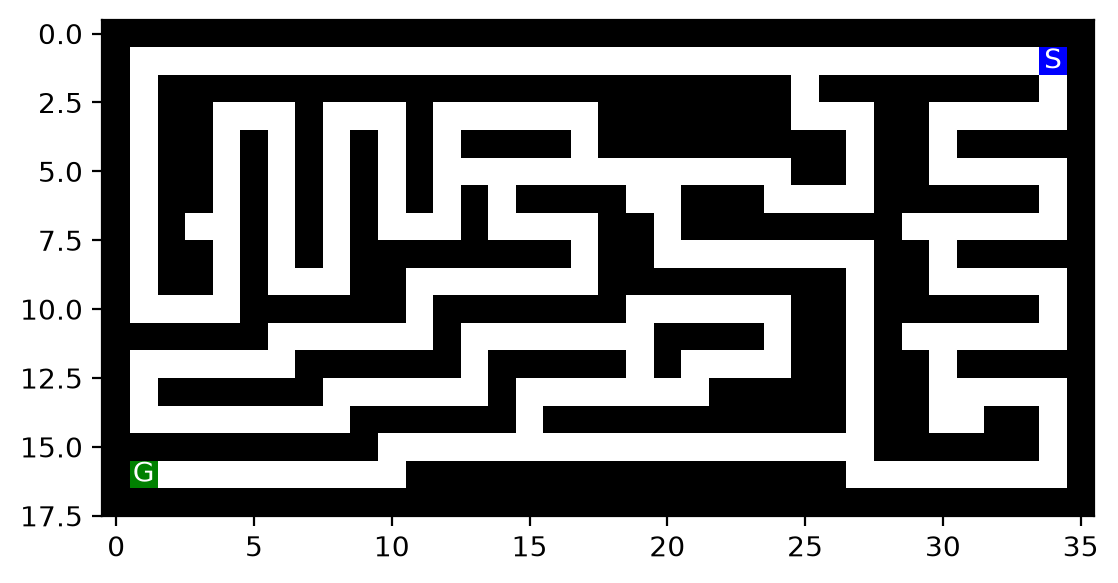

In [25]:
%run maze_helper.py
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np

#f = open("small_maze.txt", "r")
f = open("medium_maze.txt", "r")
#f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("loops_maze.txt", "r")
#f = open("L_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

# look at two positions in the maze
print("Position(0,0):", maze[0, 0])
print("Position(8,1):", maze[8, 1])

show_maze(maze)

## Implementation

My implementation follows the pseudo code from the slides/textbook.

In [26]:
# tree_search_solution.py has my actual implementation (not published)
import tree_search_solution as ts


# order in which we add new states to the frontier
ts.set_order("NESW")
#ts.set_order(random=True)

## Experiments

### BFS

In [27]:
ts.set_order("NESW")
#ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "BFS", debug = False, vis = False)
ts.show_path(maze, result)
[node.action for node in result['path'] if node.action is not None]

CPU times: total: 0 ns
Wall time: 1.3 ms
Path length: 68
Nodes expanded: 269
Max depth: 68
Max frontier: 9


['W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'S',
 'S',
 'E',
 'E',
 'S',
 'S',
 'S',
 'W',
 'W',
 'W',
 'N',
 'W',
 'W',
 'W',
 'W',
 'S',
 'S',
 'S',
 'E',
 'E',
 'E',
 'E',
 'E',
 'E',
 'E',
 'S',
 'S',
 'S',
 'S',
 'S',
 'S',
 'S',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'S',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W',
 'W']

### DFS

This implementation uses not reached data structure and has space complexity $O(bm)$ instead of $O(b^m)$ when we reuse the tree search algorithm from BFS!

We need to check for all cycles. If we do not break all cycles correctly, then we will end up in an infinite loop. Here are possible solutions:
* Stop after a fixed number of tries and return no solution `max_tries`.
* IDS solves this problem.

Note on the visualization: I use gray for areas that the algorithm has explored, but DFS has already removed it from memory!

In [28]:
# Note: DFS uses LIFO so the directions come from the stack in reverse order!

# Can get stuck for empty maze since cycle checking is not string enough!
# I use a maximum number of tries and stop if the goal is not reached.
ts.set_order("NESW")
#ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

CPU times: total: 0 ns
Wall time: 808 μs
Path length: 152
Nodes expanded: 153
Max depth: 152
Max frontier: 8


Do the same, but change the order in which we explore states (add them to them as nodes to the frontier).

In [29]:
#ts.set_order("NESW")
ts.set_order("SENW")
#ts.set_order("WSEN")
#ts.set_order(random=True)

%time result = ts.DFS(maze, vis = False, max_tries = 100000, debug_reached = True)

#result
ts.show_path(maze, result)
if result['path'] is None:
    print("No solution found!")

CPU times: total: 0 ns
Wall time: 661 μs
Path length: 152
Nodes expanded: 153
Max depth: 152
Max frontier: 8


We could do a random walk and not check for cycles. This is guaranteed to reach eventually any square including the goal,
but creates a long path. The path could be simplified leading to the [Tremaux's algorithm](https://en.wikipedia.org/wiki/Maze_solving_algorithm).

In [30]:
ts.set_order(random = True)

# run it multiple times to see the effect of randomization
for _ in range(5):
    %time result = ts.DFS(maze, check_cycle = False, max_tries = 100000, vis = False, debug_reached = True)

    #result
    ts.show_path(maze, result)
    if result['path'] is None:
        print("No solution found!")

CPU times: total: 484 ms
Wall time: 530 ms
Path length: 60898
Nodes expanded: 60898
Max depth: 60898
Max frontier: 66779
CPU times: total: 172 ms
Wall time: 200 ms
Path length: 15644
Nodes expanded: 15644
Max depth: 15644
Max frontier: 16904
CPU times: total: 250 ms
Wall time: 324 ms
Path length: 19522
Nodes expanded: 19522
Max depth: 19522
Max frontier: 21047
CPU times: total: 78.1 ms
Wall time: 63.4 ms
Path length: 4916
Nodes expanded: 4916
Max depth: 4916
Max frontier: 5232
CPU times: total: 375 ms
Wall time: 375 ms
Path length: 31908
Nodes expanded: 31908
Max depth: 31908
Max frontier: 34506


### Run randomized DFS multiple times and use the best solution.

__Note:__ IDS takes a similar amount of time and memory, but is guaranteed optimal.

In [31]:
ts.set_order(random = True)

N = 100
%time results = [ ts.DFS(maze, max_tries = 10000, vis = False) for _ in range(N) ]

# check if we found a solution and display the best solution
results = [ r for r in results if not r['path'] is None ]
if len(results) > 0:
    path_lengths = [ len(r['path'])-1 for r in results ]

    print(f"Solutions have path_lengths of {path_lengths}")

    result = results[ts.min_index(path_lengths)]
    ts.show_path(maze, result)
else:
    print("No solution found!")

CPU times: total: 297 ms
Wall time: 308 ms
Solutions have path_lengths of [244, 164, 68, 102, 152, 142, 164, 134, 68, 142, 74, 114, 114, 122, 74, 174, 110, 74, 74, 102, 74, 222, 74, 102, 74, 152, 68, 122, 174, 74, 74, 134, 102, 68, 114, 74, 130, 74, 74, 154, 68, 74, 74, 74, 130, 152, 68, 74, 74, 244, 174, 74, 130, 74, 74, 102, 150, 74, 74, 232, 164, 68, 74, 68, 134, 68, 222, 142, 134, 162, 114, 162, 142, 68, 74, 74, 152, 130, 110, 164, 74, 74, 130, 68, 74, 164, 130, 142, 152, 150, 74, 130, 74, 114, 154, 74, 134, 74, 74, 74]
Path length: 68
Nodes expanded: 281
Max depth: 179
Max frontier: 10


### Depth limited DFS

Note: The frontier needs to be checked differently during cycle checking!

In [32]:
ts.set_order(random = True)

%time result = ts.DFS(maze, limit = 5, frontier_option = 2, max_tries = 100000, vis = False, debug_reached = True)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 376 μs
No solution found!


### IDS

__Notes:__

* IDS with DFS does not store reached squares, so gray areas are not shown!

* IDS depends on the cycle checking of DFS and therefore is also affected by these problems.

In [33]:
ts.set_order(random = True)

%time result = ts.IDS(maze, frontier_option = 2, max_tries = 100000)
ts.show_path(maze, result)

CPU times: total: 141 ms
Wall time: 116 ms
Path length: 68
Nodes expanded: 9606
Max depth: 68
Max frontier: 9


### Greedy Best-First Search (GBFS)

In [34]:
# set the heuristic to Manhattan distance
ts.heuristic = ts.manhattan

In [35]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "GBFS", debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 2.37 ms
Path length: 152
Nodes expanded: 157
Max depth: 152
Max frontier: 8


### A* Search

In [36]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 15.6 ms
Wall time: 4.16 ms
Path length: 68
Nodes expanded: 222
Max depth: 68
Max frontier: 8


### Weighted A* Search

$W > 1$ tends towards GBFS (optimality is not guaranteed)

In [37]:
ts.set_order(random=True)

%time result = ts.best_first_search(maze, strategy = "A*", W = 1+1e-9, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 15.6 ms
Wall time: 3.31 ms
Path length: 68
Nodes expanded: 220
Max depth: 68
Max frontier: 8


In [38]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 5, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 1.94 ms
Path length: 74
Nodes expanded: 78
Max depth: 74
Max frontier: 4


In [39]:
%time result = ts.best_first_search(maze, strategy = "A*", W = 1000, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 2.19 ms
Path length: 152
Nodes expanded: 157
Max depth: 152
Max frontier: 8


$W<1$ tends towards Uniform-Cost Search/BFS (optimality is guaranteed)

In [40]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .7, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 3.22 ms
Path length: 68
Nodes expanded: 239
Max depth: 68
Max frontier: 7


In [41]:
%time result = ts.best_first_search(maze, strategy = "A*", W = .0001, debug = False, vis = False)
ts.show_path(maze, result)

CPU times: total: 0 ns
Wall time: 3.86 ms
Path length: 68
Nodes expanded: 268
Max depth: 68
Max frontier: 8


### Compare Timing

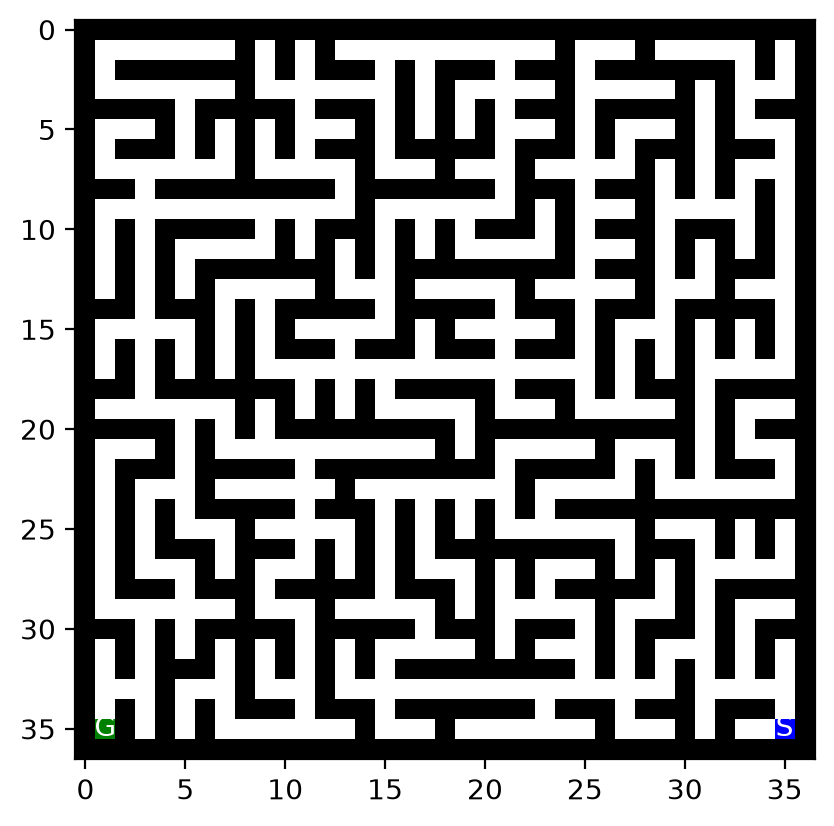

In [42]:
#f = open("small_maze.txt", "r")
#f = open("medium_maze.txt", "r")
f = open("large_maze.txt", "r")    # this has only one solution!
#f = open("open_maze.txt", "r")
#f = open("empty_maze.txt", "r")
#f = open("empty_maze_2.txt", "r")
#f = open("L_maze.txt", "r")
#f = open("loops_maze.txt", "r")

maze_str = f.read()
maze = parse_maze(maze_str)

show_maze(maze)

ts.set_order(random=True)


In [43]:
import timeit
import math

reps = 10

times = {}

algorithms = ["BFS", "DFS", "GBFS", "A*"]

### FIXME: add IDS

for a in algorithms:
    times[a] = math.ceil(timeit.timeit(stmt = f'ts.best_first_search(maze, strategy = "{a}", debug = False, vis = False)',
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['DFS(no reached)'] = math.ceil(timeit.timeit(stmt = f'ts.DFS(maze, vis = False)',
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

times['IDS'] = math.ceil(timeit.timeit(stmt = f'ts.IDS(maze, vis = False)',
              setup = 'from __main__ import ts, maze',
                    number = reps)*1e6/reps)

In [44]:
import pandas as pd
df = pd.DataFrame(times, index = ["time in micro seconds"])
df

,BFS,DFS,GBFS,A*,DFS(no reached),IDS
time in micro seconds,7080,7319,5779,6396,4854,656031


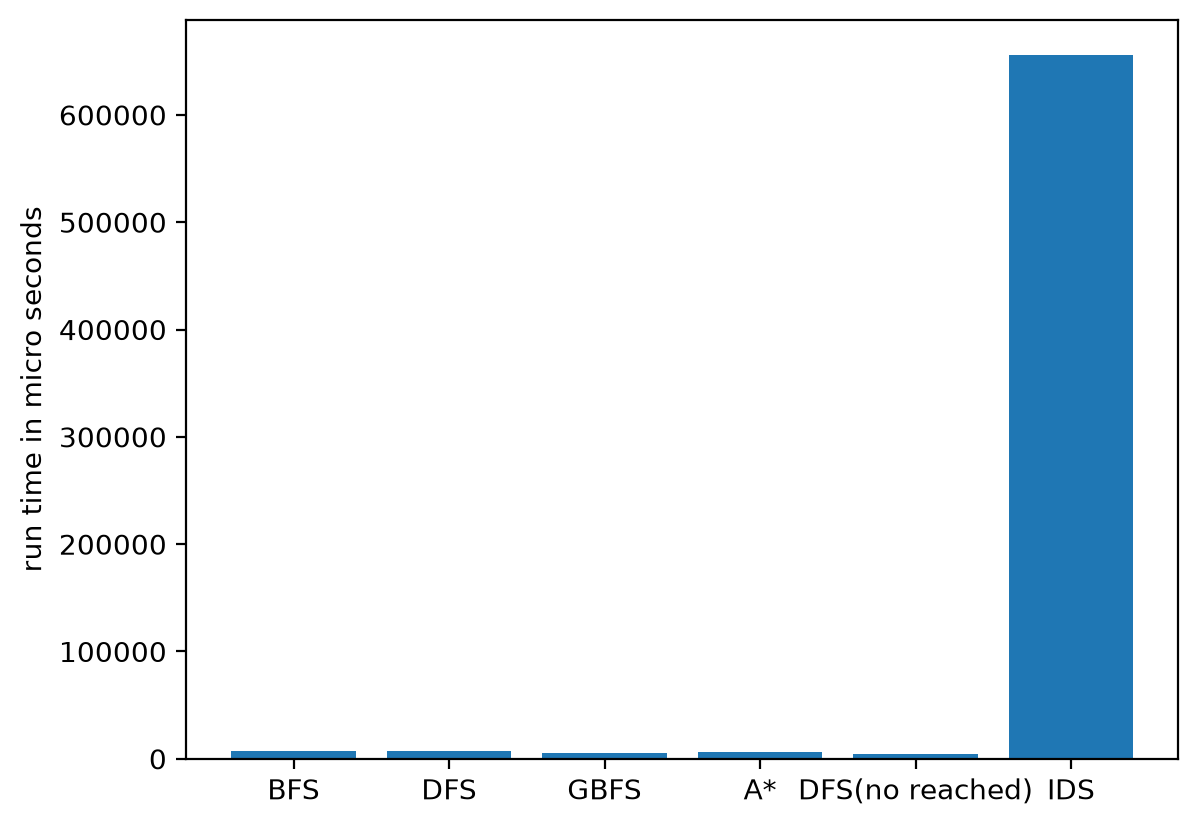

In [45]:
import matplotlib.pyplot as plt

plt.bar(df.columns, height = df.iloc[0])
plt.ylabel("run time in micro seconds")
plt.show()